# Calibração de câmeras com OpenCV

Este notebook calibra as mesmas duas câmeras e utiliza os mesmos conjuntos de imagens empregados no experimento com o método de Zhang:

- Apple iPhone 15;
- Apple iPad de 9ª geração.

São executadas duas variantes por câmera:

1. **OpenCV padrão**, com $k_1,k_2,p_1,p_2,k_3$;
2. **OpenCV restrito**, com $p_1=p_2=0$ e $k_3=0$, deixando livres essencialmente $k_1$ e $k_2$, o que aproxima o modelo de distorção utilizado no artigo de Zhang.

O OpenCV utiliza a matriz intrínseca

$$
K=
\begin{bmatrix}
f_x&0&c_x\\
0&f_y&c_y\\
0&0&1
\end{bmatrix},
$$

portanto não estima o *skew* $\gamma$ utilizado na formulação geral de Zhang.

## Estratégia de memória

As imagens completas não são mantidas simultaneamente na RAM. O fluxo é:

$$
\text{abrir uma imagem}
\rightarrow
\text{detectar os cantos}
\rightarrow
\text{armazenar apenas }(u,v)
\rightarrow
\text{liberar a imagem}
\rightarrow
\text{processar a próxima}.
$$

A detecção é realizada na resolução original. Redimensionamentos são usados apenas nas visualizações.

## 1. Dependências e configuração

O padrão utilizado possui **9 × 6 cantos internos**, com quadrados de **25 mm × 25 mm**.

Estrutura esperada:

```text
images/
├── iphone15/
└── ipad9/
```

In [1]:
from __future__ import annotations

import gc
import json
import math
import platform
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps

try:
    from pillow_heif import register_heif_opener
    register_heif_opener()
    HEIF_SUPPORT = True
except ImportError:
    HEIF_SUPPORT = False

np.set_printoptions(precision=8, suppress=True)

print(f"Python: {platform.python_version()}")
print(f"OpenCV: {cv2.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Suporte a HEIC/HEIF: {HEIF_SUPPORT}")

Python: 3.13.5
OpenCV: 5.0.0
NumPy: 2.5.3
Pandas: 3.0.6
Suporte a HEIC/HEIF: True


In [2]:
CAMERAS = {
    "iphone15": "Apple iPhone 15",
    "ipad9": "Apple iPad (9ª geração)",
}

PATTERN_SIZE = (9, 6)
SQUARE_SIZE_MM = 25.0

SUPPORTED_EXTENSIONS = {
    ".heic", ".heif",
    ".jpg", ".jpeg",
    ".png",
    ".tif", ".tiff",
}

STRICT_ALL_IMAGES = True
MAX_PREVIEW_IMAGES = 4
PREVIEW_MAX_DIMENSION = 1600

In [3]:
def find_repository_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        images_dir = candidate / "images"
        if all((images_dir / camera_id).is_dir() for camera_id in CAMERAS):
            return candidate

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do repositório contendo "
        "images/iphone15/ e images/ipad9/."
    )


ROOT = find_repository_root()
IMAGES_DIR = ROOT / "images"

RESULTS_DIR = ROOT / "results"
OPENCV_DIR = RESULTS_DIR / "opencv"
OPENCV_CALIBRATION_DIR = OPENCV_DIR / "calibration"
OPENCV_FIGURES_DIR = OPENCV_DIR / "figures"
OPENCV_TABLES_DIR = OPENCV_DIR / "tables"

for directory in (
    OPENCV_CALIBRATION_DIR,
    OPENCV_FIGURES_DIR,
    OPENCV_TABLES_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Raiz do repositório: {ROOT}")

Raiz do repositório: /Users/gabriellopesbastos/Projects/camera-calibration-zhang


## 2. Descoberta dos arquivos e normalização de orientação

Para cada câmera, a resolução/orientação mais frequente é adotada como referência. Se uma imagem possuir exatamente largura e altura invertidas em relação à referência, ela é rotacionada em $90^\circ$. Nenhum redimensionamento é aplicado aos dados usados na calibração.

Nesta etapa são armazenados apenas caminhos e metadados.

In [4]:
def discover_images(folder: Path) -> list[Path]:
    paths = sorted(
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )

    if not paths:
        raise FileNotFoundError(
            f"Nenhuma imagem suportada foi encontrada em {folder}."
        )

    has_heif = any(
        path.suffix.lower() in {".heic", ".heif"}
        for path in paths
    )

    if has_heif and not HEIF_SUPPORT:
        raise ImportError(
            "Foram encontrados arquivos HEIC/HEIF, mas pillow-heif "
            "não está instalada."
        )

    return paths


def get_oriented_image_size(path: Path) -> tuple[int, int]:
    with Image.open(path) as image:
        width, height = image.size
        orientation = image.getexif().get(274, 1)

        if orientation in {5, 6, 7, 8}:
            width, height = height, width

    return width, height


def load_image(path: Path) -> np.ndarray:
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        rgb = np.asarray(image.convert("RGB"))

    return cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)


def normalize_image_orientation(
    image: np.ndarray,
    reference_size: tuple[int, int],
) -> tuple[np.ndarray, str]:
    height, width = image.shape[:2]
    current_size = (width, height)

    if current_size == reference_size:
        return image, "original"

    if current_size == reference_size[::-1]:
        return (
            cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE),
            "rotated_90_cw",
        )

    raise ValueError(
        f"Resolução incompatível: {current_size}. "
        f"A resolução de referência é {reference_size}."
    )


def inspect_dataset(camera_id: str) -> dict:
    folder = IMAGES_DIR / camera_id
    paths = discover_images(folder)

    original_sizes = [
        get_oriented_image_size(path)
        for path in paths
    ]

    reference_size, reference_count = Counter(
        original_sizes
    ).most_common(1)[0]

    entries = []

    for path, original_size in zip(paths, original_sizes):
        if original_size == reference_size:
            normalization = "original"
        elif original_size == reference_size[::-1]:
            normalization = "rotated_90_cw"
        else:
            raise ValueError(
                f"{CAMERAS[camera_id]}: {path.name} possui "
                f"resolução {original_size}, incompatível com "
                f"a referência {reference_size}."
            )

        entries.append({
            "path": path,
            "original_size": original_size,
            "size": reference_size,
            "orientation_normalization": normalization,
        })

    return {
        "camera_id": camera_id,
        "camera_name": CAMERAS[camera_id],
        "folder": folder,
        "image_size": reference_size,
        "reference_size_count": reference_count,
        "entries": entries,
    }


datasets = {
    camera_id: inspect_dataset(camera_id)
    for camera_id in CAMERAS
}

overview_df = pd.DataFrame([
    {
        "camera": data["camera_name"],
        "folder": str(data["folder"].relative_to(ROOT)),
        "images": len(data["entries"]),
        "width_px": data["image_size"][0],
        "height_px": data["image_size"][1],
        "reference_orientation_images": data["reference_size_count"],
        "rotated_images": sum(
            entry["orientation_normalization"] != "original"
            for entry in data["entries"]
        ),
    }
    for data in datasets.values()
])

display(overview_df)

,camera,folder,images,width_px,height_px,reference_orientation_images,rotated_images
0,Apple iPhone 15,images/iphone15,41,4284,5712,35,6
1,Apple iPad (9ª geração),images/ipad9,36,2448,3264,33,3


## 3. Detecção dos cantos

A detecção é realizada na resolução original. Primeiro é utilizado `findChessboardCornersSB`; se necessário, utiliza-se o detector clássico seguido de `cornerSubPix`.

Apenas uma imagem permanece na memória por vez.

In [5]:
def detect_chessboard_corners(
    image: np.ndarray,
    pattern_size: tuple[int, int],
) -> tuple[bool, np.ndarray | None, str]:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sb_flags = (
        cv2.CALIB_CB_NORMALIZE_IMAGE
        | cv2.CALIB_CB_EXHAUSTIVE
        | cv2.CALIB_CB_ACCURACY
    )

    found, corners = cv2.findChessboardCornersSB(
        gray,
        pattern_size,
        flags=sb_flags,
    )

    if found:
        return (
            True,
            corners.reshape(-1, 2).astype(np.float64),
            "findChessboardCornersSB",
        )

    classic_flags = (
        cv2.CALIB_CB_ADAPTIVE_THRESH
        | cv2.CALIB_CB_NORMALIZE_IMAGE
    )

    found, corners = cv2.findChessboardCorners(
        gray,
        pattern_size,
        flags=classic_flags,
    )

    if not found:
        return False, None, "not_detected"

    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        50,
        1e-4,
    )

    corners = cv2.cornerSubPix(
        gray,
        corners,
        winSize=(11, 11),
        zeroZone=(-1, -1),
        criteria=criteria,
    )

    return (
        True,
        corners.reshape(-1, 2).astype(np.float64),
        "findChessboardCorners+cornerSubPix",
    )


def detect_dataset(data: dict) -> dict:
    entries = []
    total = len(data["entries"])

    for index, entry in enumerate(data["entries"], start=1):
        print(
            f"\r{data['camera_name']}: "
            f"processando {index}/{total} — {entry['path'].name}",
            end="",
        )

        image = load_image(entry["path"])
        image, normalization = normalize_image_orientation(
            image,
            data["image_size"],
        )

        found, image_points, method = detect_chessboard_corners(
            image,
            PATTERN_SIZE,
        )

        entries.append({
            **entry,
            "orientation_normalization": normalization,
            "pattern_detected": bool(found),
            "image_points": image_points,
            "detection_method": method,
        })

        del image
        gc.collect()

    print()

    return {
        **data,
        "entries": entries,
    }


datasets = {
    camera_id: detect_dataset(data)
    for camera_id, data in datasets.items()
}

Apple iPhone 15: processando 41/41 — IMG_9249.HEIC
Apple iPad (9ª geração): processando 36/36 — IMG_0179.HEIC


In [6]:
detection_rows = []

for data in datasets.values():
    for entry in data["entries"]:
        detection_rows.append({
            "camera_id": data["camera_id"],
            "camera": data["camera_name"],
            "file": entry["path"].name,
            "original_width_px": entry["original_size"][0],
            "original_height_px": entry["original_size"][1],
            "orientation_normalization": entry["orientation_normalization"],
            "pattern_detected": entry["pattern_detected"],
            "detection_method": entry["detection_method"],
        })

detection_df = pd.DataFrame(detection_rows)

detection_summary_df = (
    detection_df
    .groupby(["camera_id", "camera"], as_index=False)
    .agg(
        images=("file", "count"),
        detected=("pattern_detected", "sum"),
    )
)

detection_summary_df["failed"] = (
    detection_summary_df["images"]
    - detection_summary_df["detected"]
)

display(detection_summary_df)

failed_df = detection_df.loc[
    ~detection_df["pattern_detected"]
]

if not failed_df.empty:
    display(failed_df)
else:
    print("O padrão foi detectado em todas as imagens.")

,camera_id,camera,images,detected,failed
0,ipad9,Apple iPad (9ª geração),36,36,0
1,iphone15,Apple iPhone 15,41,41,0


O padrão foi detectado em todas as imagens.


In [7]:
if STRICT_ALL_IMAGES and not failed_df.empty:
    raise RuntimeError(
        "A execução foi interrompida porque STRICT_ALL_IMAGES=True "
        "e o padrão não foi detectado em todas as imagens."
    )

## 4. Inspeção visual

As imagens são carregadas novamente apenas para inspeção. A redução de tamanho ocorre somente no *preview* e não altera os pontos utilizados na calibração.

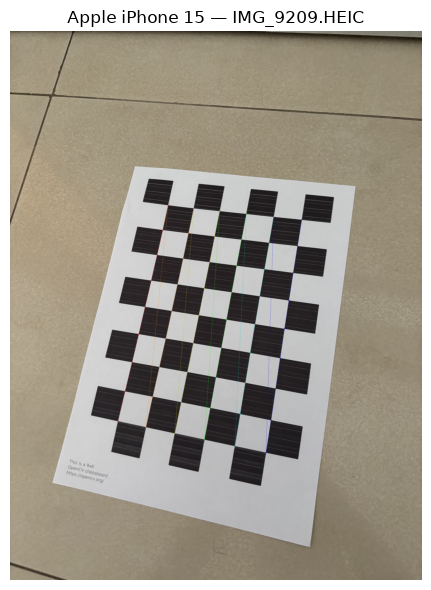

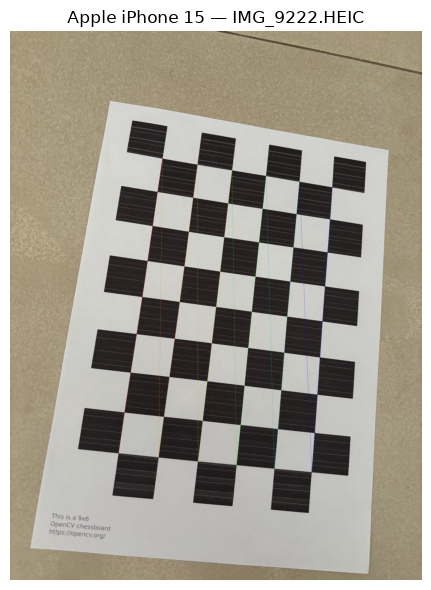

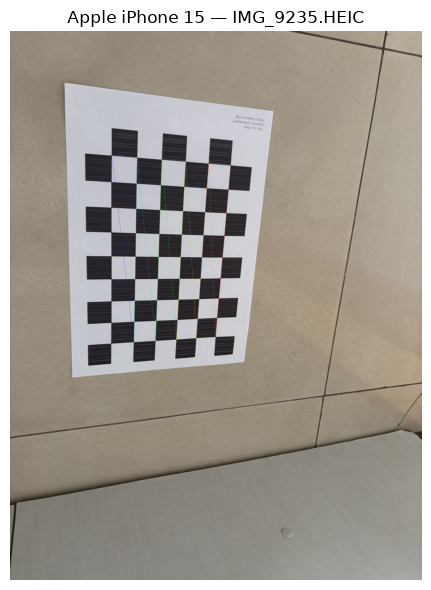

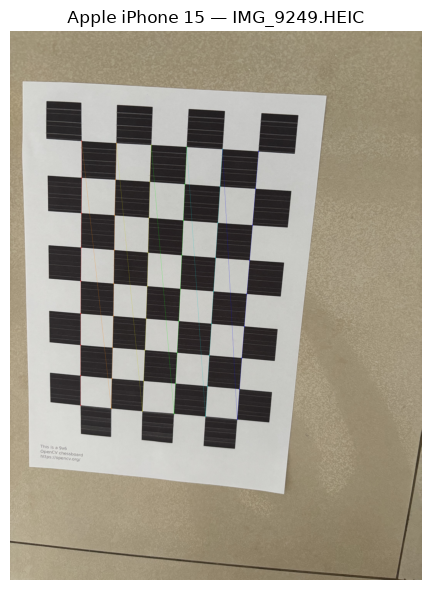

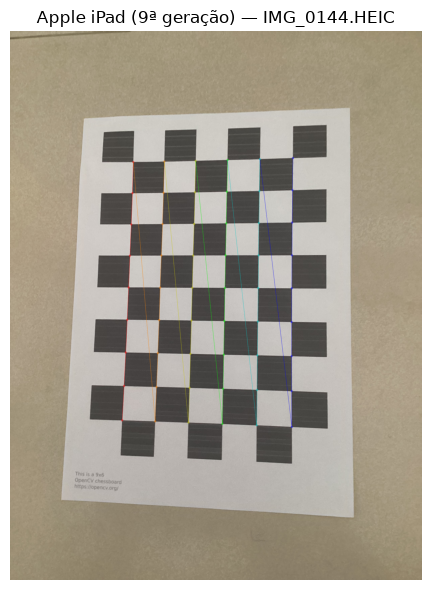

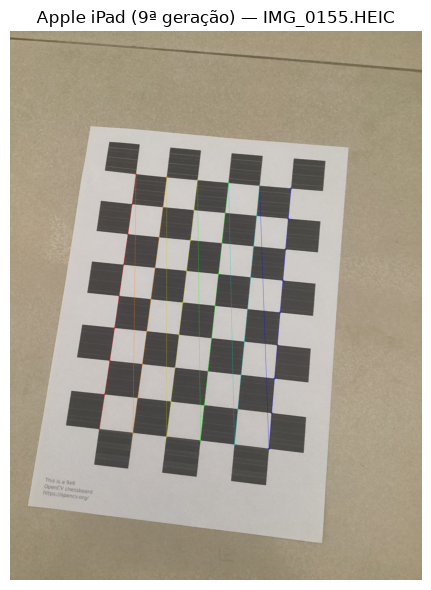

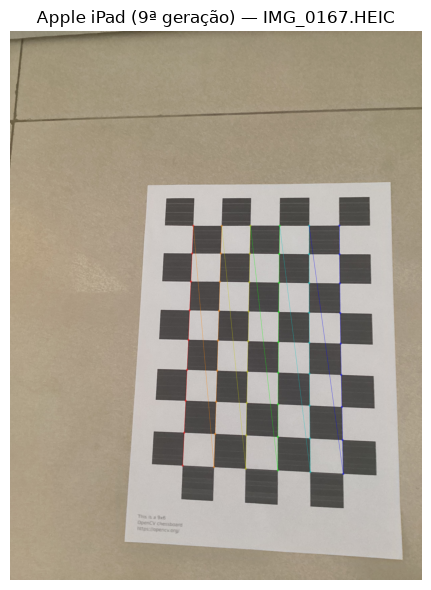

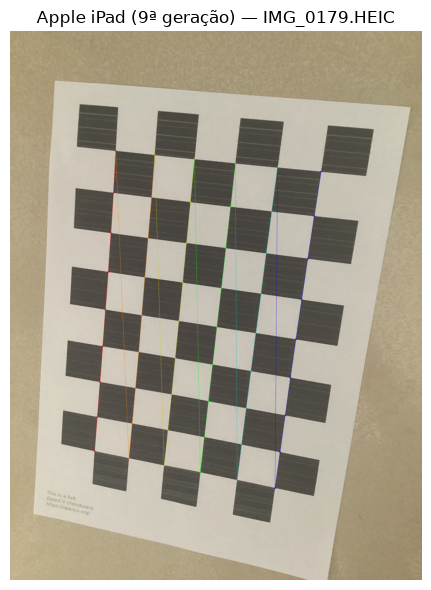

In [8]:
def show_detection_previews(
    data: dict,
    max_images: int = MAX_PREVIEW_IMAGES,
) -> None:
    valid_entries = [
        entry
        for entry in data["entries"]
        if entry["pattern_detected"]
    ]

    if not valid_entries:
        return

    indices = np.linspace(
        0,
        len(valid_entries) - 1,
        min(max_images, len(valid_entries)),
        dtype=int,
    )

    for index in indices:
        entry = valid_entries[index]

        image = load_image(entry["path"])
        image, _ = normalize_image_orientation(
            image,
            data["image_size"],
        )

        preview = image.copy()

        cv2.drawChessboardCorners(
            preview,
            PATTERN_SIZE,
            entry["image_points"]
            .reshape(-1, 1, 2)
            .astype(np.float32),
            True,
        )

        height, width = preview.shape[:2]

        if max(width, height) > PREVIEW_MAX_DIMENSION:
            scale = PREVIEW_MAX_DIMENSION / max(width, height)

            preview = cv2.resize(
                preview,
                (
                    int(round(width * scale)),
                    int(round(height * scale)),
                ),
                interpolation=cv2.INTER_AREA,
            )

        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
        plt.title(f"{data['camera_name']} — {entry['path'].name}")
        plt.axis("off")
        plt.tight_layout()
        plt.show()
        plt.close()

        del image
        del preview
        gc.collect()


for data in datasets.values():
    show_detection_previews(data)

## 5. Pontos 3D do padrão

Para o OpenCV, cada canto é representado por $(X,Y,Z)$. Como o padrão é planar,

$$
Z=0.
$$

Os pontos estão expressos em milímetros.

In [9]:
def create_object_points(
    pattern_size: tuple[int, int],
    square_size_mm: float,
) -> np.ndarray:
    cols, rows = pattern_size

    points = np.zeros(
        (rows * cols, 3),
        dtype=np.float32,
    )

    points[:, :2] = (
        np.mgrid[0:cols, 0:rows]
        .T
        .reshape(-1, 2)
    )

    points[:, :2] *= square_size_mm

    return points


OBJECT_POINTS = create_object_points(
    PATTERN_SIZE,
    SQUARE_SIZE_MM,
)

print(f"Número de pontos do padrão: {len(OBJECT_POINTS)}")
print(OBJECT_POINTS[:5])

Número de pontos do padrão: 54
[[  0.   0.   0.]
 [ 25.   0.   0.]
 [ 50.   0.   0.]
 [ 75.   0.   0.]
 [100.   0.   0.]]


In [10]:
def prepare_opencv_points(
    data: dict,
):
    valid_entries = [
        entry
        for entry in data["entries"]
        if entry["pattern_detected"]
    ]

    object_points = [
        OBJECT_POINTS.copy()
        for _ in valid_entries
    ]

    image_points = [
        entry["image_points"]
        .reshape(-1, 1, 2)
        .astype(np.float32)
        for entry in valid_entries
    ]

    return object_points, image_points, valid_entries

## 6. OpenCV padrão

Nesta configuração, `cv2.calibrateCamera` estima $f_x,f_y,c_x,c_y$ e os coeficientes

$$
k_1,k_2,p_1,p_2,k_3.
$$

In [11]:
def calibrate_opencv_standard(data: dict) -> dict:
    object_points, image_points, valid_entries = prepare_opencv_points(data)

    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
        object_points,
        image_points,
        data["image_size"],
        cameraMatrix=None,
        distCoeffs=None,
        flags=0,
    )

    return {
        "variant": "standard",
        "camera_id": data["camera_id"],
        "camera_name": data["camera_name"],
        "image_size": data["image_size"],
        "valid_entries": valid_entries,
        "object_points": object_points,
        "image_points": image_points,
        "rms_opencv": float(rms),
        "camera_matrix": K,
        "distortion_coefficients": dist.ravel(),
        "rvecs": rvecs,
        "tvecs": tvecs,
    }


opencv_standard = {
    camera_id: calibrate_opencv_standard(data)
    for camera_id, data in datasets.items()
}

## 7. OpenCV restrito

Para aproximar o modelo de distorção utilizado no artigo de Zhang, são impostas:

$$
p_1=p_2=0
$$

e

$$
k_3=0.
$$

Assim, permanecem livres $k_1$ e $k_2$. A comparação ainda não é idêntica ao Zhang porque o OpenCV mantém *skew* igual a zero.

In [12]:
OPENCV_RESTRICTED_FLAGS = (
    cv2.CALIB_ZERO_TANGENT_DIST
    | cv2.CALIB_FIX_K3
)


def calibrate_opencv_restricted(data: dict) -> dict:
    object_points, image_points, valid_entries = prepare_opencv_points(data)

    initial_dist = np.zeros(
        (5, 1),
        dtype=np.float64,
    )

    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
        object_points,
        image_points,
        data["image_size"],
        cameraMatrix=None,
        distCoeffs=initial_dist,
        flags=OPENCV_RESTRICTED_FLAGS,
    )

    return {
        "variant": "restricted",
        "camera_id": data["camera_id"],
        "camera_name": data["camera_name"],
        "image_size": data["image_size"],
        "valid_entries": valid_entries,
        "object_points": object_points,
        "image_points": image_points,
        "rms_opencv": float(rms),
        "camera_matrix": K,
        "distortion_coefficients": dist.ravel(),
        "rvecs": rvecs,
        "tvecs": tvecs,
    }


opencv_restricted = {
    camera_id: calibrate_opencv_restricted(data)
    for camera_id, data in datasets.items()
}

## 8. Resultados das calibrações

In [13]:
for camera_id in CAMERAS:
    for calibration in (
        opencv_standard[camera_id],
        opencv_restricted[camera_id],
    ):
        print("=" * 72)
        print(
            f"{calibration['camera_name']} — "
            f"{calibration['variant']}"
        )
        print(
            f"RMS retornado pelo OpenCV: "
            f"{calibration['rms_opencv']:.6f} px"
        )
        print("\nMatriz K:")
        print(calibration["camera_matrix"])
        print("\nCoeficientes de distorção:")
        print(calibration["distortion_coefficients"])
        print()

Apple iPhone 15 — standard
RMS retornado pelo OpenCV: 1.382109 px

Matriz K:
[[4363.49546098    0.         2127.17646131]
 [   0.         4367.98664727 2844.41125222]
 [   0.            0.            1.        ]]

Coeficientes de distorção:
[ 0.30163714 -1.98216272 -0.00041345 -0.00045101  3.88911872]

Apple iPhone 15 — restricted
RMS retornado pelo OpenCV: 1.736630 px

Matriz K:
[[4388.19040964    0.         2133.09496117]
 [   0.         4392.24877001 2845.63249967]
 [   0.            0.            1.        ]]

Coeficientes de distorção:
[ 0.15265199 -0.53505597  0.          0.          0.        ]

Apple iPad (9ª geração) — standard
RMS retornado pelo OpenCV: 0.869817 px

Matriz K:
[[2964.69776881    0.         1224.37907649]
 [   0.         2970.53882685 1604.41148064]
 [   0.            0.            1.        ]]

Coeficientes de distorção:
[-0.00208592  1.35864088 -0.00143432  0.00058848 -5.30702   ]

Apple iPad (9ª geração) — restricted
RMS retornado pelo OpenCV: 0.921926 px

M

## 9. Erro de reprojeção

O RMSE por imagem é

$$
\operatorname{RMSE}_i=
\sqrt{
\frac{1}{m}
\sum_j
\left\|
m_{ij}-\hat m_{ij}
\right\|^2
}.
$$

Também é calculado um RMSE global sobre todos os pontos de todas as vistas.

In [14]:
def compute_reprojection_errors(
    calibration: dict,
):
    rows = []
    total_squared_error = 0.0
    total_points = 0

    for (
        entry,
        object_points,
        observed_points,
        rvec,
        tvec,
    ) in zip(
        calibration["valid_entries"],
        calibration["object_points"],
        calibration["image_points"],
        calibration["rvecs"],
        calibration["tvecs"],
    ):
        projected_points, _ = cv2.projectPoints(
            object_points,
            rvec,
            tvec,
            calibration["camera_matrix"],
            calibration["distortion_coefficients"],
        )

        observed = observed_points.reshape(-1, 2)
        projected = projected_points.reshape(-1, 2)

        residuals = projected - observed
        squared_norms = np.sum(residuals ** 2, axis=1)
        distances = np.sqrt(squared_norms)

        rmse = math.sqrt(np.mean(squared_norms))

        total_squared_error += float(np.sum(squared_norms))
        total_points += len(squared_norms)

        rows.append({
            "camera_id": calibration["camera_id"],
            "camera": calibration["camera_name"],
            "variant": calibration["variant"],
            "file": entry["path"].name,
            "rmse_px": float(rmse),
            "mean_error_px": float(np.mean(distances)),
            "median_error_px": float(np.median(distances)),
            "max_error_px": float(np.max(distances)),
        })

    global_rmse = math.sqrt(
        total_squared_error / total_points
    )

    return pd.DataFrame(rows), float(global_rmse)


reprojection_frames = []
global_rows = []

for camera_id in CAMERAS:
    for calibration in (
        opencv_standard[camera_id],
        opencv_restricted[camera_id],
    ):
        errors_df, global_rmse = compute_reprojection_errors(
            calibration
        )

        calibration["global_rmse_px"] = global_rmse

        reprojection_frames.append(errors_df)

        global_rows.append({
            "camera_id": camera_id,
            "camera": calibration["camera_name"],
            "variant": calibration["variant"],
            "opencv_returned_rms_px": calibration["rms_opencv"],
            "computed_global_rmse_px": global_rmse,
        })


reprojection_df = pd.concat(
    reprojection_frames,
    ignore_index=True,
)

global_rmse_df = pd.DataFrame(global_rows)

global_rmse_df["absolute_difference_px"] = (
    global_rmse_df["opencv_returned_rms_px"]
    - global_rmse_df["computed_global_rmse_px"]
).abs()

display(global_rmse_df)

,camera_id,camera,variant,opencv_returned_rms_px,computed_global_rmse_px,absolute_difference_px
0,iphone15,Apple iPhone 15,standard,1.382109,1.382107,2.630490e-06
1,iphone15,Apple iPhone 15,restricted,1.736630,1.736629,8.508859e-07
2,ipad9,Apple iPad (9ª geração),standard,0.869817,0.869819,1.315287e-06
3,ipad9,Apple iPad (9ª geração),restricted,0.921926,0.921925,1.161599e-06


## 10. Comparação entre as variantes OpenCV

In [15]:
def distortion_value(
    calibration: dict,
    index: int,
) -> float:
    coeffs = calibration["distortion_coefficients"]

    if index < len(coeffs):
        return float(coeffs[index])

    return 0.0


summary_rows = []

for camera_id in CAMERAS:
    for calibration in (
        opencv_standard[camera_id],
        opencv_restricted[camera_id],
    ):
        K = calibration["camera_matrix"]

        summary_rows.append({
            "camera_id": camera_id,
            "camera": calibration["camera_name"],
            "variant": calibration["variant"],
            "width_px": calibration["image_size"][0],
            "height_px": calibration["image_size"][1],
            "images_used": len(calibration["valid_entries"]),
            "fx_px": float(K[0, 0]),
            "fy_px": float(K[1, 1]),
            "cx_px": float(K[0, 2]),
            "cy_px": float(K[1, 2]),
            "k1": distortion_value(calibration, 0),
            "k2": distortion_value(calibration, 1),
            "p1": distortion_value(calibration, 2),
            "p2": distortion_value(calibration, 3),
            "k3": distortion_value(calibration, 4),
            "global_rmse_px": calibration["global_rmse_px"],
        })


opencv_summary_df = pd.DataFrame(summary_rows)
display(opencv_summary_df)

,camera_id,camera,variant,width_px,height_px,images_used,fx_px,fy_px,cx_px,cy_px,k1,k2,p1,p2,k3,global_rmse_px
0,iphone15,Apple iPhone 15,standard,4284,5712,41,4363.495461,4367.986647,2127.176461,2844.411252,0.301637,-1.982163,-0.000413,-0.000451,3.889119,1.382107
1,iphone15,Apple iPhone 15,restricted,4284,5712,41,4388.190410,4392.248770,2133.094961,2845.632500,0.152652,-0.535056,0.000000,0.000000,0.000000,1.736629
2,ipad9,Apple iPad (9ª geração),standard,2448,3264,36,2964.697769,2970.538827,1224.379076,1604.411481,-0.002086,1.358641,-0.001434,0.000588,-5.307020,0.869819
3,ipad9,Apple iPad (9ª geração),restricted,2448,3264,36,2957.340860,2963.083226,1220.347804,1612.404109,0.103152,-0.080863,0.000000,0.000000,0.000000,0.921925


In [16]:
variant_difference_rows = []

for camera_id, camera_name in CAMERAS.items():
    subset = (
        opencv_summary_df
        .loc[opencv_summary_df["camera_id"] == camera_id]
        .set_index("variant")
    )

    standard = subset.loc["standard"]
    restricted = subset.loc["restricted"]

    row = {
        "camera_id": camera_id,
        "camera": camera_name,
    }

    for parameter in (
        "fx_px",
        "fy_px",
        "cx_px",
        "cy_px",
        "k1",
        "k2",
        "global_rmse_px",
    ):
        a = float(standard[parameter])
        b = float(restricted[parameter])

        row[f"{parameter}_absolute_difference"] = abs(a - b)

        row[f"{parameter}_relative_difference_pct"] = (
            abs(b - a) / abs(a) * 100.0
            if abs(a) > 1e-15
            else np.nan
        )

    variant_difference_rows.append(row)


variant_difference_df = pd.DataFrame(
    variant_difference_rows
)

display(variant_difference_df)

,camera_id,camera,fx_px_absolute_difference,fx_px_relative_difference_pct,fy_px_absolute_difference,fy_px_relative_difference_pct,cx_px_absolute_difference,cx_px_relative_difference_pct,cy_px_absolute_difference,cy_px_relative_difference_pct,k1_absolute_difference,k1_relative_difference_pct,k2_absolute_difference,k2_relative_difference_pct,global_rmse_px_absolute_difference,global_rmse_px_relative_difference_pct
0,iphone15,Apple iPhone 15,24.694949,0.565944,24.262123,0.555453,5.918500,0.278233,1.221247,0.042935,0.148985,49.392178,1.447107,73.006456,0.354522,25.650840
1,ipad9,Apple iPad (9ª geração),7.356909,0.248150,7.455601,0.250985,4.031272,0.329250,7.992628,0.498166,0.105238,5045.157163,1.439504,105.951791,0.052106,5.990484


## 11. Gráficos de erro de reprojeção

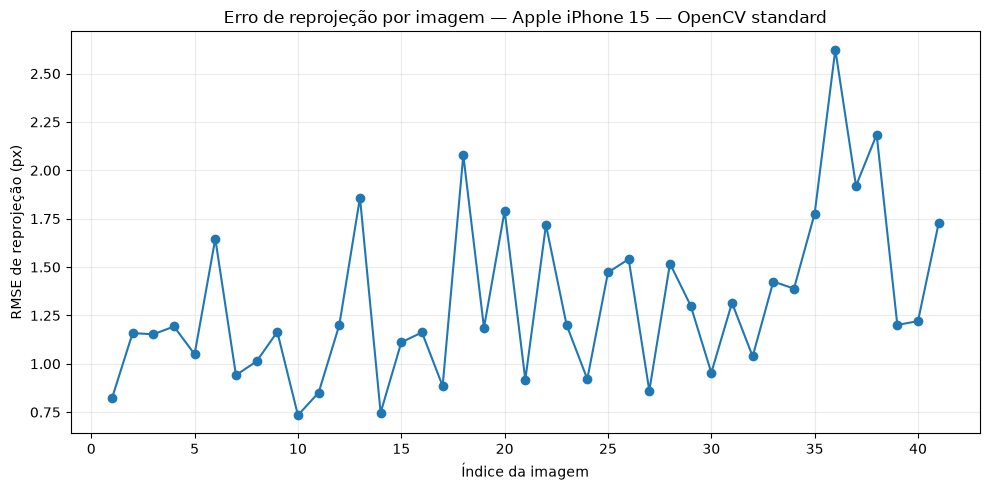

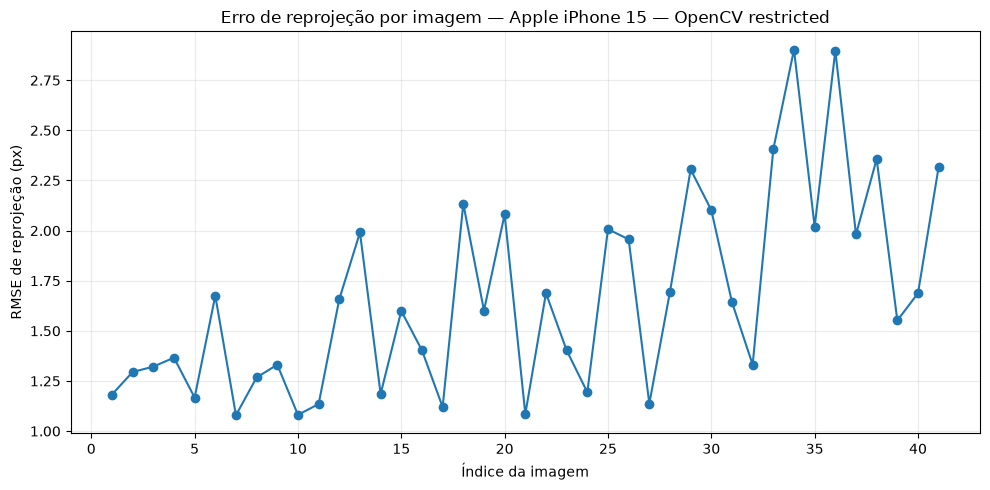

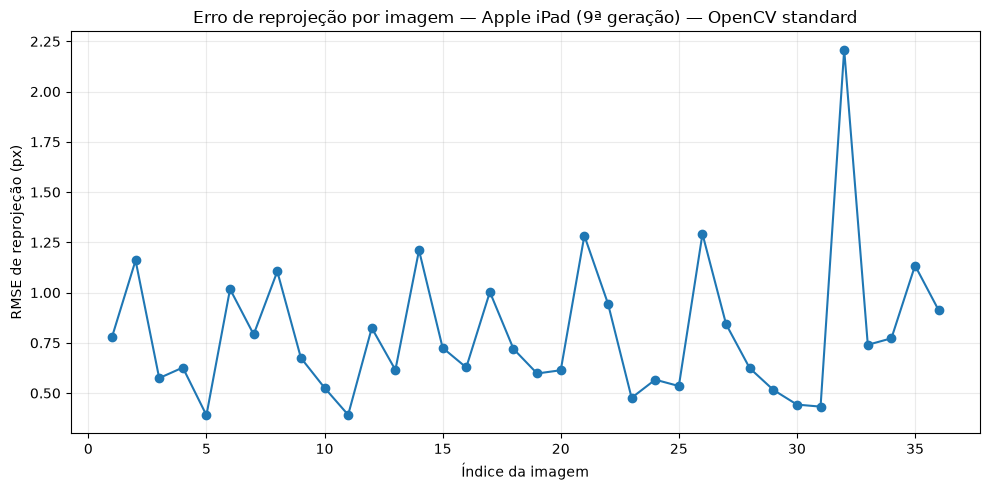

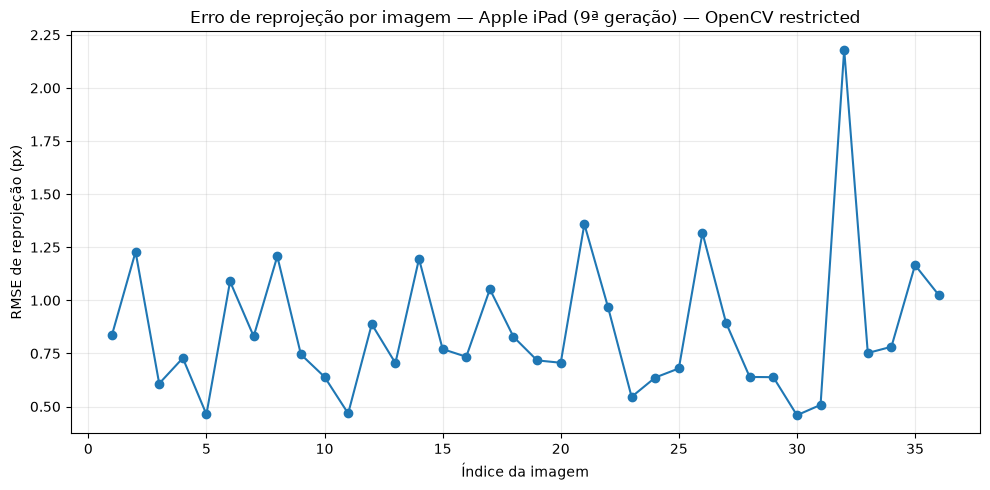

In [17]:
for camera_id, camera_name in CAMERAS.items():
    for variant in ("standard", "restricted"):
        subset = (
            reprojection_df
            .loc[
                (reprojection_df["camera_id"] == camera_id)
                & (reprojection_df["variant"] == variant)
            ]
            .reset_index(drop=True)
        )

        plt.figure(figsize=(10, 5))
        plt.plot(
            np.arange(1, len(subset) + 1),
            subset["rmse_px"],
            marker="o",
        )
        plt.xlabel("Índice da imagem")
        plt.ylabel("RMSE de reprojeção (px)")
        plt.title(
            f"Erro de reprojeção por imagem — "
            f"{camera_name} — OpenCV {variant}"
        )
        plt.grid(True, alpha=0.25)
        plt.tight_layout()

        output_path = (
            OPENCV_FIGURES_DIR
            / f"{camera_id}_{variant}_reprojection_error.png"
        )

        plt.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

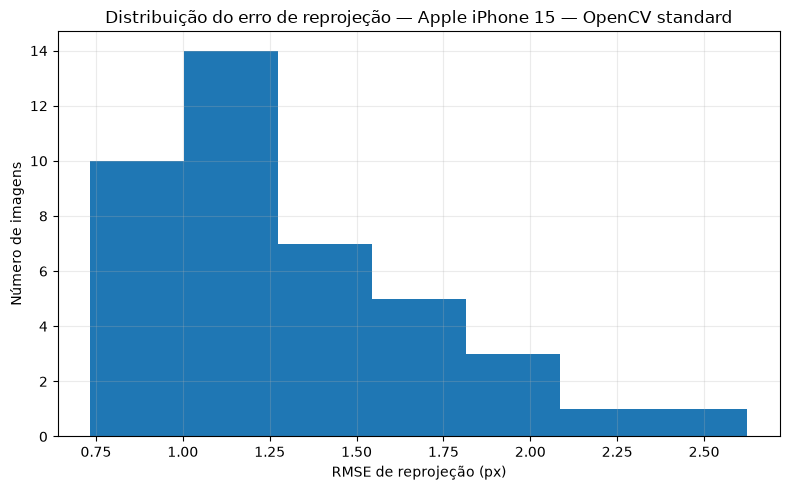

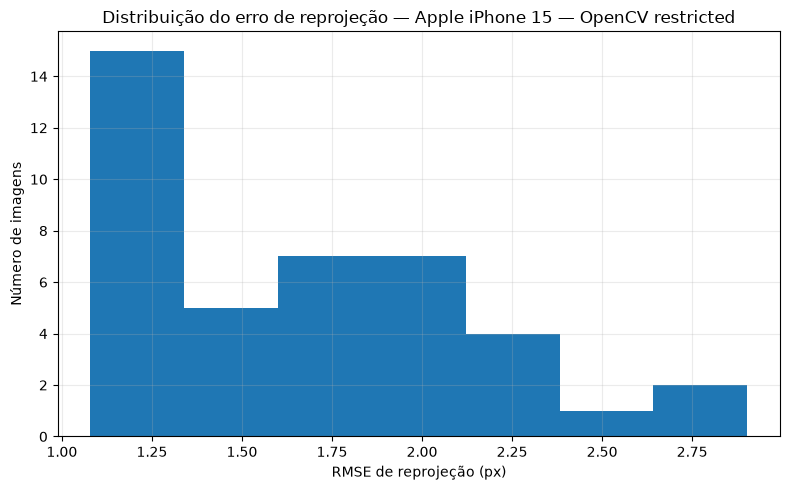

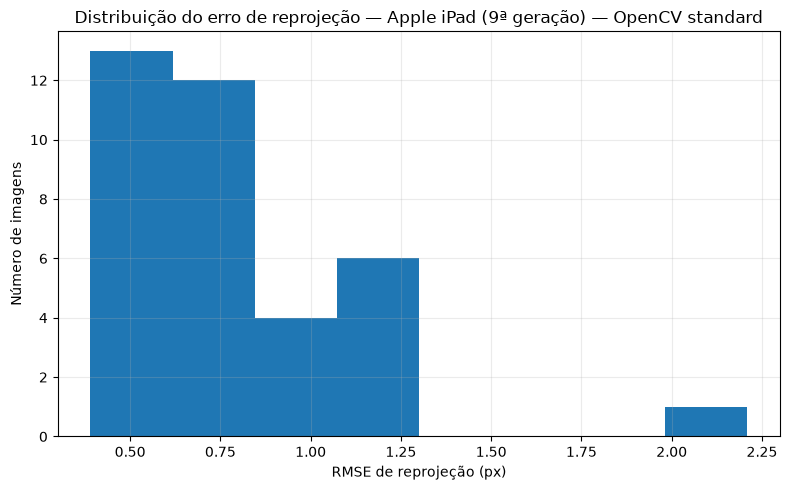

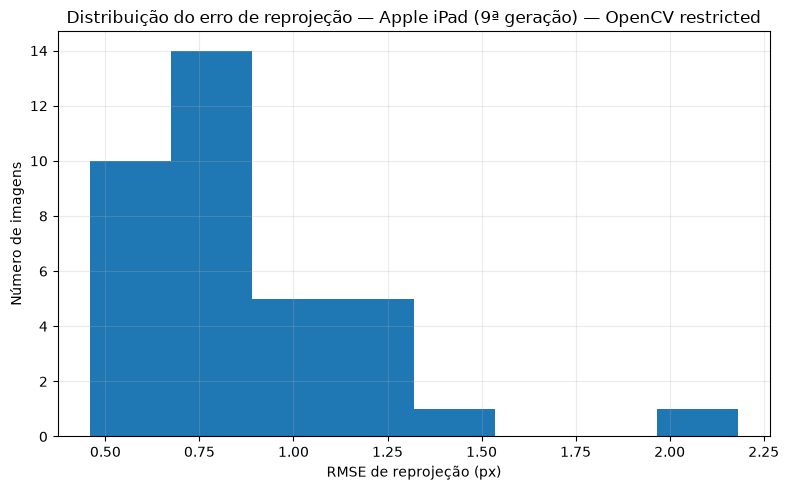

In [18]:
for camera_id, camera_name in CAMERAS.items():
    for variant in ("standard", "restricted"):
        subset = reprojection_df.loc[
            (reprojection_df["camera_id"] == camera_id)
            & (reprojection_df["variant"] == variant),
            "rmse_px",
        ]

        plt.figure(figsize=(8, 5))
        plt.hist(subset, bins="auto")
        plt.xlabel("RMSE de reprojeção (px)")
        plt.ylabel("Número de imagens")
        plt.title(
            f"Distribuição do erro de reprojeção — "
            f"{camera_name} — OpenCV {variant}"
        )
        plt.grid(True, alpha=0.25)
        plt.tight_layout()

        output_path = (
            OPENCV_FIGURES_DIR
            / f"{camera_id}_{variant}_reprojection_histogram.png"
        )

        plt.savefig(
            output_path,
            dpi=200,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

## 12. Comparação automática com o resultado de Zhang

Se existirem:

```text
results/calibration/iphone15.json
results/calibration/ipad9.json
```

o notebook lê os parâmetros finais do refinamento de máxima verossimilhança e os compara com as duas variantes do OpenCV.

In [19]:
ZHANG_DIR = RESULTS_DIR / "calibration"


def load_zhang_result(camera_id: str):
    path = ZHANG_DIR / f"{camera_id}.json"

    if not path.exists():
        return None

    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


zhang_results = {
    camera_id: load_zhang_result(camera_id)
    for camera_id in CAMERAS
}

zhang_available = all(
    result is not None
    for result in zhang_results.values()
)

print(
    "Resultados de Zhang encontrados."
    if zhang_available
    else "Resultados de Zhang não encontrados para todas as câmeras."
)

Resultados de Zhang encontrados.


In [20]:
zhang_comparison_df = None
zhang_difference_df = None

if zhang_available:
    rows = []

    for camera_id, camera_name in CAMERAS.items():
        zhang = zhang_results[camera_id]
        refined = zhang["maximum_likelihood_refinement"]

        K_zhang = np.asarray(
            refined["camera_matrix"],
            dtype=float,
        )

        k_zhang = refined["radial_distortion"]

        rows.append({
            "camera_id": camera_id,
            "camera": camera_name,
            "method": "Zhang",
            "fx_px": float(K_zhang[0, 0]),
            "fy_px": float(K_zhang[1, 1]),
            "cx_px": float(K_zhang[0, 2]),
            "cy_px": float(K_zhang[1, 2]),
            "gamma_px": float(K_zhang[0, 1]),
            "k1": float(k_zhang["k1"]),
            "k2": float(k_zhang["k2"]),
            "global_rmse_px": float(
                refined["final_global_rmse_px"]
            ),
        })

        for calibration in (
            opencv_standard[camera_id],
            opencv_restricted[camera_id],
        ):
            K = calibration["camera_matrix"]

            rows.append({
                "camera_id": camera_id,
                "camera": camera_name,
                "method": (
                    "OpenCV padrão"
                    if calibration["variant"] == "standard"
                    else "OpenCV restrito"
                ),
                "fx_px": float(K[0, 0]),
                "fy_px": float(K[1, 1]),
                "cx_px": float(K[0, 2]),
                "cy_px": float(K[1, 2]),
                "gamma_px": 0.0,
                "k1": distortion_value(calibration, 0),
                "k2": distortion_value(calibration, 1),
                "global_rmse_px": calibration["global_rmse_px"],
            })

    zhang_comparison_df = pd.DataFrame(rows)
    display(zhang_comparison_df)

    difference_rows = []

    for camera_id, camera_name in CAMERAS.items():
        subset = (
            zhang_comparison_df
            .loc[zhang_comparison_df["camera_id"] == camera_id]
            .set_index("method")
        )

        zhang = subset.loc["Zhang"]

        for method in ("OpenCV padrão", "OpenCV restrito"):
            other = subset.loc[method]

            row = {
                "camera_id": camera_id,
                "camera": camera_name,
                "comparison": f"Zhang vs {method}",
            }

            for parameter in (
                "fx_px",
                "fy_px",
                "cx_px",
                "cy_px",
                "k1",
                "k2",
                "global_rmse_px",
            ):
                a = float(zhang[parameter])
                b = float(other[parameter])

                row[f"{parameter}_absolute_difference"] = abs(b - a)
                row[f"{parameter}_relative_difference_pct"] = (
                    abs(b - a) / abs(a) * 100.0
                    if abs(a) > 1e-15
                    else np.nan
                )

            difference_rows.append(row)

    zhang_difference_df = pd.DataFrame(difference_rows)
    display(zhang_difference_df)

,camera_id,camera,method,fx_px,fy_px,cx_px,cy_px,gamma_px,k1,k2,global_rmse_px
0,iphone15,Apple iPhone 15,Zhang,4389.466675,4393.467817,2144.224021,2846.219169,7.969228,0.154811,-0.540099,1.598534
1,iphone15,Apple iPhone 15,OpenCV padrão,4363.495461,4367.986647,2127.176461,2844.411252,0.000000,0.301637,-1.982163,1.382107
2,iphone15,Apple iPhone 15,OpenCV restrito,4388.190410,4392.248770,2133.094961,2845.632500,0.000000,0.152652,-0.535056,1.736629
3,ipad9,Apple iPad (9ª geração),Zhang,2948.704912,2954.382360,1227.847962,1618.602958,5.466973,0.105240,-0.087329,0.861216
4,ipad9,Apple iPad (9ª geração),OpenCV padrão,2964.697769,2970.538827,1224.379076,1604.411481,0.000000,-0.002086,1.358641,0.869819
5,ipad9,Apple iPad (9ª geração),OpenCV restrito,2957.340860,2963.083226,1220.347804,1612.404109,0.000000,0.103152,-0.080863,0.921925


,camera_id,camera,comparison,fx_px_absolute_difference,fx_px_relative_difference_pct,fy_px_absolute_difference,fy_px_relative_difference_pct,cx_px_absolute_difference,cx_px_relative_difference_pct,cy_px_absolute_difference,cy_px_relative_difference_pct,k1_absolute_difference,k1_relative_difference_pct,k2_absolute_difference,k2_relative_difference_pct,global_rmse_px_absolute_difference,global_rmse_px_relative_difference_pct
0,iphone15,Apple iPhone 15,Zhang vs OpenCV padrão,25.971214,0.591671,25.481170,0.579979,17.047560,0.795046,1.807917,0.063520,0.146826,94.842552,1.442063,266.999596,0.216427,13.539120
1,iphone15,Apple iPhone 15,Zhang vs OpenCV restrito,1.276265,0.029076,1.219047,0.027747,11.129060,0.519025,0.586670,0.020612,0.002159,1.394429,0.005043,0.933802,0.138095,8.638822
2,ipad9,Apple iPad (9ª geração),Zhang vs OpenCV padrão,15.992856,0.542369,16.156467,0.546864,3.468885,0.282518,14.191478,0.876773,0.107326,101.982049,1.445970,1655.776205,0.008603,0.998882
3,ipad9,Apple iPad (9ª geração),Zhang vs OpenCV restrito,8.635947,0.292873,8.700866,0.294507,7.500158,0.610838,6.198849,0.382975,0.002089,1.984580,0.006465,7.403450,0.060709,7.049204


## 13. Exportação dos resultados

Os artefatos são gravados em:

```text
results/opencv/
├── calibration/
├── figures/
└── tables/
```

In [21]:
DISTORTION_NAMES = [
    "k1",
    "k2",
    "p1",
    "p2",
    "k3",
]


def calibration_to_json(calibration: dict) -> dict:
    K = calibration["camera_matrix"]
    coeffs = calibration["distortion_coefficients"]

    distortion = {
        name: (
            float(coeffs[index])
            if index < len(coeffs)
            else 0.0
        )
        for index, name in enumerate(DISTORTION_NAMES)
    }

    errors = (
        reprojection_df
        .loc[
            (reprojection_df["camera_id"] == calibration["camera_id"])
            & (reprojection_df["variant"] == calibration["variant"])
        ]
        .drop(columns=["camera_id", "camera", "variant"])
        .to_dict(orient="records")
    )

    extrinsics = []

    for entry, rvec, tvec in zip(
        calibration["valid_entries"],
        calibration["rvecs"],
        calibration["tvecs"],
    ):
        R, _ = cv2.Rodrigues(rvec)

        extrinsics.append({
            "file": entry["path"].name,
            "rotation_matrix": R.astype(float).tolist(),
            "rotation_vector": (
                np.asarray(rvec)
                .reshape(-1)
                .astype(float)
                .tolist()
            ),
            "translation_mm": (
                np.asarray(tvec)
                .reshape(-1)
                .astype(float)
                .tolist()
            ),
        })

    return {
        "method": "OpenCV calibrateCamera",
        "variant": calibration["variant"],
        "camera_id": calibration["camera_id"],
        "camera": calibration["camera_name"],
        "image_resolution_px": {
            "width": int(calibration["image_size"][0]),
            "height": int(calibration["image_size"][1]),
        },
        "calibration_pattern": {
            "type": "planar chessboard",
            "inner_corners": {
                "columns": int(PATTERN_SIZE[0]),
                "rows": int(PATTERN_SIZE[1]),
            },
            "square_size_mm": float(SQUARE_SIZE_MM),
        },
        "images": {
            "used": int(len(calibration["valid_entries"])),
        },
        "camera_matrix": K.astype(float).tolist(),
        "intrinsic_parameters_px": {
            "fx": float(K[0, 0]),
            "fy": float(K[1, 1]),
            "cx": float(K[0, 2]),
            "cy": float(K[1, 2]),
            "gamma": 0.0,
        },
        "distortion_coefficients": distortion,
        "opencv_returned_rms_px": float(calibration["rms_opencv"]),
        "computed_global_rmse_px": float(calibration["global_rmse_px"]),
        "extrinsics": extrinsics,
        "per_image_reprojection_error": errors,
        "environment": {
            "python": platform.python_version(),
            "opencv": cv2.__version__,
            "numpy": np.__version__,
            "pandas": pd.__version__,
        },
    }


for camera_id in CAMERAS:
    for calibration in (
        opencv_standard[camera_id],
        opencv_restricted[camera_id],
    ):
        output_path = (
            OPENCV_CALIBRATION_DIR
            / f"{camera_id}_{calibration['variant']}.json"
        )

        with output_path.open("w", encoding="utf-8") as file:
            json.dump(
                calibration_to_json(calibration),
                file,
                indent=2,
                ensure_ascii=False,
            )

        print(f"Salvo: {output_path.relative_to(ROOT)}")

Salvo: results/opencv/calibration/iphone15_standard.json
Salvo: results/opencv/calibration/iphone15_restricted.json
Salvo: results/opencv/calibration/ipad9_standard.json
Salvo: results/opencv/calibration/ipad9_restricted.json


In [22]:
opencv_summary_df.to_csv(
    OPENCV_TABLES_DIR / "opencv_calibration_summary.csv",
    index=False,
)

variant_difference_df.to_csv(
    OPENCV_TABLES_DIR / "opencv_variant_differences.csv",
    index=False,
)

reprojection_df.to_csv(
    OPENCV_TABLES_DIR / "opencv_reprojection_errors.csv",
    index=False,
)

detection_df.to_csv(
    OPENCV_TABLES_DIR / "opencv_detection_summary.csv",
    index=False,
)

global_rmse_df.to_csv(
    OPENCV_TABLES_DIR / "opencv_global_rmse.csv",
    index=False,
)

if zhang_comparison_df is not None:
    zhang_comparison_df.to_csv(
        OPENCV_TABLES_DIR / "zhang_opencv_comparison.csv",
        index=False,
    )

if zhang_difference_df is not None:
    zhang_difference_df.to_csv(
        OPENCV_TABLES_DIR / "zhang_opencv_differences.csv",
        index=False,
    )

## 14. Verificação final

In [23]:
expected_outputs = [
    OPENCV_CALIBRATION_DIR / "iphone15_standard.json",
    OPENCV_CALIBRATION_DIR / "iphone15_restricted.json",
    OPENCV_CALIBRATION_DIR / "ipad9_standard.json",
    OPENCV_CALIBRATION_DIR / "ipad9_restricted.json",
    OPENCV_TABLES_DIR / "opencv_calibration_summary.csv",
    OPENCV_TABLES_DIR / "opencv_variant_differences.csv",
    OPENCV_TABLES_DIR / "opencv_reprojection_errors.csv",
    OPENCV_TABLES_DIR / "opencv_detection_summary.csv",
    OPENCV_TABLES_DIR / "opencv_global_rmse.csv",
]

output_status_df = pd.DataFrame([
    {
        "file": str(path.relative_to(ROOT)),
        "exists": path.exists(),
    }
    for path in expected_outputs
])

display(output_status_df)

if not output_status_df["exists"].all():
    raise RuntimeError(
        "Um ou mais artefatos esperados não foram produzidos."
    )

print("Calibração OpenCV concluída.")

,file,exists
0,results/opencv/calibration/iphone15_standard.json,True
1,results/opencv/calibration/iphone15_restricted...,True
2,results/opencv/calibration/ipad9_standard.json,True
3,results/opencv/calibration/ipad9_restricted.json,True
4,results/opencv/tables/opencv_calibration_summa...,True
5,results/opencv/tables/opencv_variant_differenc...,True
6,results/opencv/tables/opencv_reprojection_erro...,True
7,results/opencv/tables/opencv_detection_summary...,True
8,results/opencv/tables/opencv_global_rmse.csv,True


Calibração OpenCV concluída.


## 15. Síntese

As duas variantes utilizam exatamente as mesmas correspondências $(X,Y,Z)\leftrightarrow(u,v)$.

A comparação resultante permite separar dois efeitos:

- diferenças causadas pelo modelo de distorção do OpenCV;
- diferenças entre a implementação explícita do método de Zhang e a rotina `cv2.calibrateCamera`.

O OpenCV restrito é a referência mais próxima do modelo radial de Zhang, enquanto o OpenCV padrão fornece uma calibração com maior liberdade para representar distorções tangenciais e o terceiro termo radial.